# Road Damage Detection — Model Comparison (Notebook 2)
Compares models against the **YOLOv8s India baseline** from Notebook 1.

| Experiment | Model | Trained on | Tested on |
|---|---|---|---|
| Baseline (done) | YOLOv8s | India | India test |
| A | YOLOv8n (small, fast) | India | India test |
| B | YOLOv8m (bigger, more accurate) | India | India test |
| C | YOLOv8s | **All 6 countries** | India test |

**Every session:** Runtime → T4 GPU, then run the **Startup** cell first.
Each experiment can be run on a different day. If Colab disconnects, run Startup, then that experiment's **Resume** cell.

## Startup — run this first, every session

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics huggingface_hub

import glob, os, random, time, yaml
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

PROJECT = '/content/drive/MyDrive/RDD_Project'
DATA = '/content/RDD2022/data'

# Restore the India subset from Drive (saved in Notebook 1)
if not os.path.exists(DATA):
    !unzip -q -o {PROJECT}/rdd2022_india.zip -d /content

with open(f'{DATA}/data.yaml') as f:
    names = yaml.safe_load(f)['names']
if isinstance(names, list):
    names = {i: n for i, n in enumerate(names)}

india_cfg = {'path': DATA, 'train': 'images/train', 'val': 'images/valid',
             'test': 'images/test', 'names': names}
with open('/content/rdd_india.yaml', 'w') as f:
    yaml.safe_dump(india_cfg, f, sort_keys=False)

def train_run(weights, data, name, epochs):
    model = YOLO(weights)
    model.train(data=data, epochs=epochs, imgsz=640, batch=16, patience=15,
                project=f'{PROJECT}/runs', name=name, exist_ok=True)

def resume_run(name):
    YOLO(f'{PROJECT}/runs/{name}/weights/last.pt').train(resume=True)

print('Ready. India test images:',
      len(glob.glob(f'{DATA}/images/test/**/*.jpg', recursive=True)))

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 11.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ready. India test images: 1166


## Experiment A — YOLOv8n on India
Smallest and fastest model. About 1 min per epoch, ~1 hour total.

In [ ]:
train_run('yolov8n.pt', '/content/rdd_india.yaml', 'yolov8n_india', epochs=50)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_india.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_india, nbs=64, nms=None, opset=None, optimize=False, optimi

**Resume A** (only if it disconnected — run Startup first):

In [ ]:
resume_run('yolov8n_india')

      43/50      2.47G      1.613      1.908       1.69          3        640: 100% ━━━━━━━━━━━━ 336/336 4.5it/s 1:15
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 3.3it/s 11.2s
                   all       1172        743      0.458      0.446      0.365       0.17

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      44/50      2.47G      1.603      1.892      1.682          7        640: 100% ━━━━━━━━━━━━ 336/336 4.4it/s 1:17
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 3.3it/s 11.1s
                   all       1172        743      0.375      0.461      0.384      0.175

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      45/50      2.47G      1.587      1.833      1.676          2        640: 100% ━━━━━━━━━━━━ 336/336 4.5it/s 1:15
                 Class     Images  Instances      Box(

## Experiment B — YOLOv8m on India
Bigger model. About 3–4 min per epoch, ~3 hours total — expect to resume once or twice.

In [ ]:
train_run('yolov8m.pt', '/content/rdd_india.yaml', 'yolov8m_india', epochs=50)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_india.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8m_india, nbs=64, nms=None, opset=None, optimize=False, optimi

**Resume B** (only if it disconnected — run Startup first):

In [ ]:
resume_run('yolov8m_india')

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_india.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/RDD_Project/runs/yolov8m_india/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov

## Experiment C — YOLOv8s on ALL countries, validated on India
Tests whether more data (especially more transverse cracks) helps on Indian roads.

**Step C1 — download the full dataset (11 GB).** Needed in every session where you train or resume C.
It is not backed up to Drive because it would fill your free 15 GB; re-downloading from Hugging Face takes a few minutes.

In [ ]:
import glob
print(len(glob.glob('/content/RDD2022_full/data/**/*.*', recursive=True)), 'files already downloaded')

53747 files already downloaded


In [ ]:
from google.colab import userdata
from huggingface_hub import snapshot_download

try:
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print('Token loaded')
except Exception:
    print('No token found - download will be slower')

snapshot_download(
    repo_id="dronefreak/RDD2022", repo_type="dataset",
    local_dir="/content/RDD2022_full",
    allow_patterns=["data/images/train/*", "data/labels/train/*"],
    max_workers=16,
)
n = len(glob.glob('/content/RDD2022_full/data/images/train/**/*.jpg', recursive=True))
print('All-country training images:', n)

# Save to Drive (-0 = no compression, faster; images are already compressed)
%cd /content
!zip -qr -0 {PROJECT}/rdd2022_all_train.zip RDD2022_full
!ls -lh {PROJECT}/rdd2022_all_train.zip

Token loaded


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 53747 files:   0%|          | 0/53747 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/dronefreak/RDD2022/72b01f94c2e5bfe430861afd73995f2d412b8855/data%2Flabels%2Ftrain%2Fshard_000%2FChina_MotorBike_000002.txt?%2Fdatasets%2Fdronefreak%2FRDD2022%2Fresolve%2F72b01f94c2e5bfe430861afd73995f2d412b8855%2Fdata%2Flabels%2Ftrain%2Fshard_000%2FChina_MotorBike_000002.txt=&etag=%221e8f8d9c30beebd701c5921ca97be8bee613e110%22
HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/dronefreak/RDD2022/72b01f94c2e5bfe430861afd73995f2d412b8855/data%2Flabels%2Ftrain%2Fshard_000%2FChina_MotorBike_000020.txt?%2Fdatasets%2Fdronefreak%2FRDD2022%2Fresolve%2F72b01f94c2e5bfe430861afd73995f2d412b8855%2Fdata%2Flabels%2Ftrain%2Fshard_000%2FChina_MotorBike_000020.txt=&etag=%22724f66e168431c61d1faca337cb39a8318fb8d20%22
HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/dronefreak/RDD2022/72b01f94c2e5bfe430861afd73995f2d412b8855/dat

All-country training images: 26869
/content
-rw------- 1 root root 7.3G Oct 14 06:09 /content/drive/MyDrive/RDD_Project/rdd2022_all_train.zip


In [ ]:
import glob
imgs = len(glob.glob('/content/RDD2022_full/data/images/train/**/*.jpg', recursive=True))
lbls = len(glob.glob('/content/RDD2022_full/data/labels/train/**/*.txt', recursive=True))
print('Images:', imgs, '| Labels:', lbls)

%cd /content
!rm -f {PROJECT}/rdd2022_all_train.zip
!zip -qr -0 {PROJECT}/rdd2022_all_train.zip RDD2022_full
!ls -lh {PROJECT}/rdd2022_all_train.zip

Images: 26869 | Labels: 26869
/content
-rw------- 1 root root 7.3G Oct 14 06:33 /content/drive/MyDrive/RDD_Project/rdd2022_all_train.zip


In [ ]:
from google.colab import drive
drive.flush_and_unmount()
print('Drive synced')

Drive not mounted, so nothing to flush and unmount.
Drive synced


**Step C2 — train.** ~5× more images than India alone, so each epoch takes ~7 min.
20 epochs (~2.5 hours) keeps it within Colab's limits; with this much data, fewer epochs are enough.

**Step-C1b**

Run C1b after Startup




In [ ]:
if not os.path.exists('/content/RDD2022_full'):
    !unzip -q {PROJECT}/rdd2022_all_train.zip -d /content

all_cfg = {
    'train': '/content/RDD2022_full/data/images/train',   # all 6 countries
    'val':   f'{DATA}/images/valid',                       # India only
    'names': names,
}
with open('/content/rdd_all.yaml', 'w') as f:
    yaml.safe_dump(all_cfg, f, sort_keys=False)
print('Training images:', len(glob.glob('/content/RDD2022_full/data/images/train/**/*.jpg', recursive=True)))

Training images: 26869


In [ ]:
train_run('yolov8s.pt', '/content/rdd_all.yaml', 'yolov8s_all', epochs=20)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_all.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_all, nbs=64, nms=None, opset=None, optimize=False, optimizer=

**Resume C** (if it disconnected — run Startup ):

In [ ]:
resume_run('yolov8s_all')

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_all.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/RDD_Project/runs/yolov8s_all/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_a

## Comparison — evaluate every finished model on the India test set
Runs whichever models have finished; you can re-run it after each new experiment.
Measures accuracy, per-class AP, speed (FPS at batch size 1) and model size.
Results are saved to Drive as `comparison.csv`, `per_class_ap.csv` and `comparison.png`.

In [ ]:
runs = {
    'YOLOv8s (India) – baseline': 'yolov8s_india',
    'YOLOv8n (India)':            'yolov8n_india',
    'YOLOv8m (India)':            'yolov8m_india',
    'YOLOv8s (All countries)':    'yolov8s_all',
    'YOLOv8s (All → India fine-tuned)': 'yolov8s_all_ft_india',
}

test_imgs = sorted(glob.glob(f'{DATA}/images/test/**/*.jpg', recursive=True))
random.seed(0)
speed_imgs = random.sample(test_imgs, 100)

rows, class_rows = [], []
for label, run in runs.items():
    w = f'{PROJECT}/runs/{run}/weights/best.pt'
    if not os.path.exists(w):
        print(f'Skipping {label}: not trained yet')
        continue
    model = YOLO(w)
    m = model.val(data='/content/rdd_india.yaml', split='test', verbose=False,
                  project=f'{PROJECT}/runs', name=f'{run}_test', exist_ok=True)

    # Speed: batch size 1, after warm-up
    for p in speed_imgs[:5]:
        model.predict(p, verbose=False)
    t0 = time.perf_counter()
    for p in speed_imgs:
        model.predict(p, verbose=False)
    fps = len(speed_imgs) / (time.perf_counter() - t0)

    params = sum(p.numel() for p in model.model.parameters()) / 1e6
    rows.append({
        'Model': label,
        'mAP@0.5': round(m.box.map50, 4),
        'mAP@0.5:0.95': round(m.box.map, 4),
        'Precision': round(m.box.mp, 4),
        'Recall': round(m.box.mr, 4),
        'FPS (T4, batch 1)': round(fps, 1),
        'Params (M)': round(params, 1),
        'Size (MB)': round(os.path.getsize(w) / 1e6, 1),
    })
    ap = dict(zip(m.ap_class_index, m.box.ap50))
    class_rows.append({'Model': label,
                       **{names[i]: round(float(ap.get(i, 0.0)), 4) for i in names}})

results = pd.DataFrame(rows)
per_class = pd.DataFrame(class_rows)
results.to_csv(f'{PROJECT}/comparison.csv', index=False)
per_class.to_csv(f'{PROJECT}/per_class_ap.csv', index=False)

print('\n=== Overall (India test set) ===')
display(results)
print('\n=== AP@0.5 per class ===')
display(per_class)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1520.1±493.7 MB/s, size: 68.0 KB)
val: Scanning /content/RDD2022/data/labels/test/shard_000.cache... 1166 images, 725 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1166/1166 29.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 3.6it/s 20.3s
                   all       1166        723      0.363      0.333      0.316      0.139
Speed: 1.3ms preprocess, 12.5ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/drive/MyDrive/RDD_Project/runs/yolov8s_india_test
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2208.2±82

,Model,mAP@0.5,mAP@0.5:0.95,Precision,Recall,"FPS (T4, batch 1)",Params (M),Size (MB)
0,YOLOv8s (India) – baseline,0.3164,0.1391,0.3634,0.3335,49.0,11.1,22.5
1,YOLOv8n (India),0.3059,0.1426,0.5735,0.3477,78.1,3.0,6.3
2,YOLOv8m (India),0.3031,0.1376,0.5985,0.3148,21.2,25.9,52.0
3,YOLOv8s (All countries),0.3227,0.1533,0.3557,0.3263,49.6,11.1,22.5
4,YOLOv8s (All → India fine-tuned),0.3651,0.1727,0.4181,0.4271,49.4,11.1,22.5



=== AP@0.5 per class ===


,Model,longitudinal_crack,transverse_crack,alligator_crack,pothole
0,YOLOv8s (India) – baseline,0.2675,0.0015,0.6364,0.3601
1,YOLOv8n (India),0.2570,0.0014,0.6298,0.3354
2,YOLOv8m (India),0.2473,0.0042,0.6217,0.3392
3,YOLOv8s (All countries),0.3055,0.0494,0.5895,0.3464
4,YOLOv8s (All → India fine-tuned),0.3505,0.0799,0.6403,0.3898


## Comparison charts (for the report)

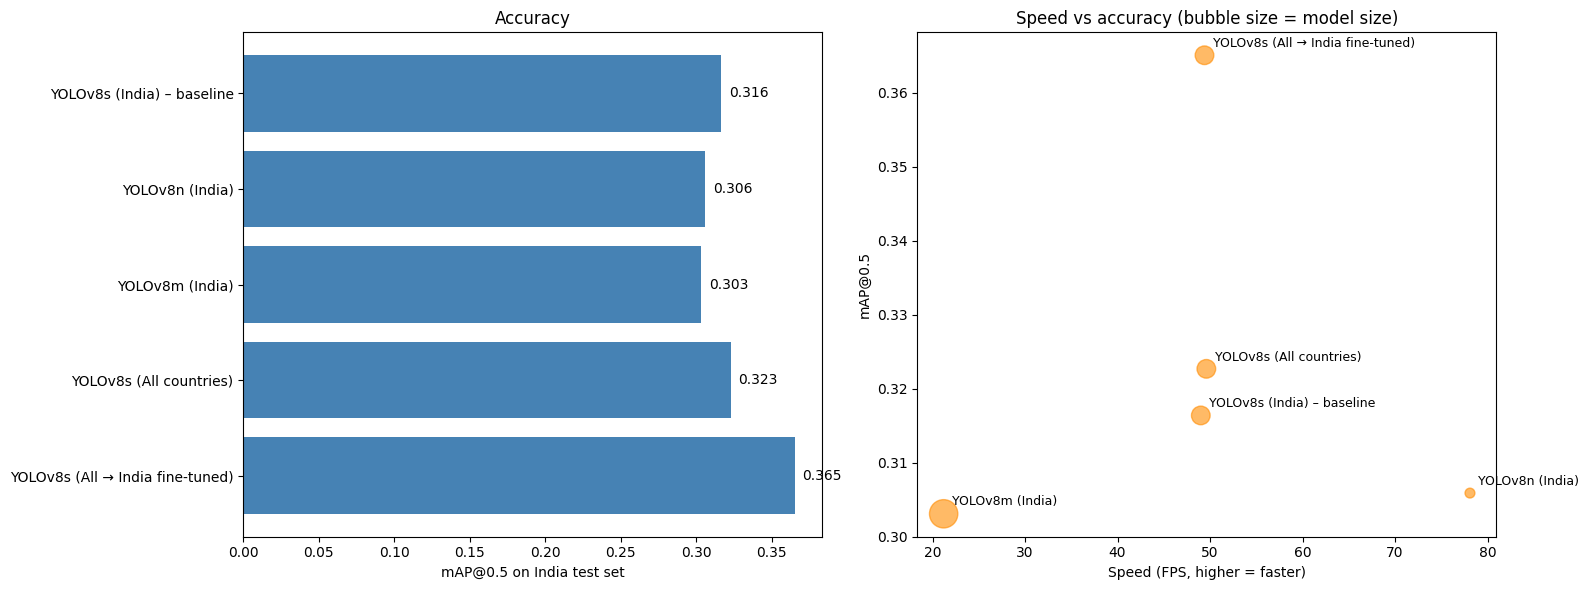

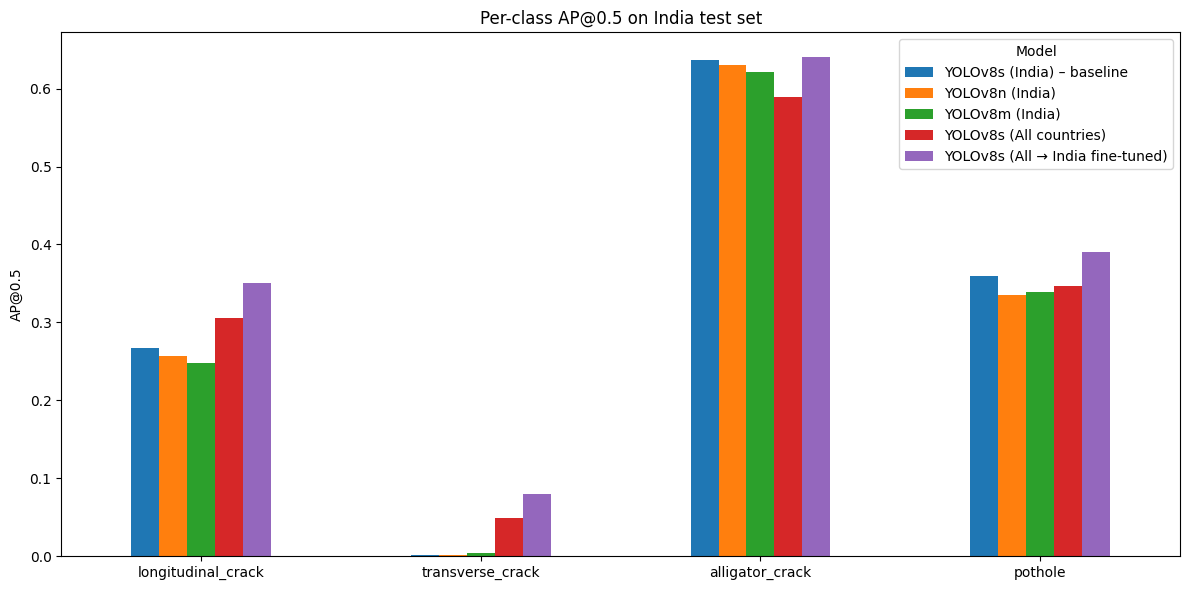

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.barh(results['Model'], results['mAP@0.5'], color='steelblue')
for i, v in enumerate(results['mAP@0.5']):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center')
ax.set_xlabel('mAP@0.5 on India test set'); ax.set_title('Accuracy')
ax.invert_yaxis()

ax = axes[1]
ax.scatter(results['FPS (T4, batch 1)'], results['mAP@0.5'], s=results['Size (MB)'] * 8,
           alpha=0.6, color='darkorange')
for _, r in results.iterrows():
    ax.annotate(r['Model'], (r['FPS (T4, batch 1)'], r['mAP@0.5']),
                textcoords='offset points', xytext=(6, 6), fontsize=9)
ax.set_xlabel('Speed (FPS, higher = faster)'); ax.set_ylabel('mAP@0.5')
ax.set_title('Speed vs accuracy (bubble size = model size)')

plt.tight_layout()
plt.savefig(f'{PROJECT}/comparison.png', dpi=150)
plt.show()

per_class.set_index('Model').T.plot(kind='bar', figsize=(12, 6), rot=0)
plt.ylabel('AP@0.5'); plt.title('Per-class AP@0.5 on India test set')
plt.tight_layout()
plt.savefig(f'{PROJECT}/per_class_comparison.png', dpi=150)
plt.show()

**Part 1: Experiment D (fine-tune on India)**

In [ ]:
model = YOLO(f'{PROJECT}/runs/yolov8s_all/weights/best.pt')   # start from the all-countries model
model.train(
    data='/content/rdd_india.yaml',
    epochs=15, imgsz=640, batch=16, patience=10,
    optimizer='AdamW', lr0=0.001,      # small learning rate = gentle fine-tuning
    project=f'{PROJECT}/runs', name='yolov8s_all_ft_india', exist_ok=True,
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd_india.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/RDD_Project/runs/yolov8s_all/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_a

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c0023b7f850>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [ ]:
import random, shutil
os.makedirs(f'{PROJECT}/demo_images', exist_ok=True)
imgs = glob.glob(f'{DATA}/images/test/**/*.jpg', recursive=True)
random.seed(7)
for p in random.sample(imgs, 15):
    shutil.copy(p, f'{PROJECT}/demo_images/')
print('Copied', len(os.listdir(f'{PROJECT}/demo_images')), 'images to Drive: RDD_Project/demo_images')

Copied 15 images to Drive: RDD_Project/demo_images
